In [1]:
import matplotlib.pyplot as plt
import numpy as np

from decomps.ldlt import ldlt_factor
from decomps.lup import lup_factor
from metrics import backward_error_1, condition_1_estimate, relative_error
from solvers.ldlt_solve import ldlt_solve
from solvers.lup_solve import lup_solve

RESERVOIRS = 20
INFLOW = 1e-3
LEVEL_DIFFERENCE = 5.0
MODES = range(1, 11)

# g[i - 1] = g_i -- коэффициент трубы i между резервуарами i - 1 и i
g = 10.0 ** (-3 + 4 * np.arange(RESERVOIRS) / 19)

1. Составление системы

In [2]:
def build_kirchhoff(g):
    n = len(g) + 1
    K = np.zeros((n, n))
    for i in range(1, n):
        a, b = i - 1, i
        K[a, a] += g[i - 1]
        K[b, b] += g[i - 1]
        K[a, b] -= g[i - 1]
        K[b, a] -= g[i - 1]
    return K


K = build_kirchhoff(g)
K_hat = K[1:, 1:]
print("Размер K:", K.shape, " размер K_hat:", K_hat.shape)

Размер K: (21, 21)  размер K_hat: (20, 20)


In [3]:
np.set_printoptions(formatter={"float_kind": lambda x: f"{x:.4e}"})


def show_row(i):
    """Строка K_hat для резервуара i (в K_hat у него индекс i - 1)."""
    row = K_hat[i - 1]
    nonzero = np.nonzero(row)[0]
    print(f"Резервуар {i}: ненулевые элементы в столбцах (резервуары) {nonzero + 1}")
    print(f"  значения: {row[nonzero]}")


for i in [1, 10, RESERVOIRS]:
    show_row(i)

print()
print(f"g_1 + g_2   = {g[0] + g[1]:.4e},   -g_2  = {-g[1]:.4e}")
print(f"-g_10 = {-g[9]:.4e},   g_10 + g_11 = {g[9] + g[10]:.4e},   -g_11 = {-g[10]:.4e}")
print(f"-g_20 = {-g[19]:.4e},   g_20 = {g[19]:.4e}")

Резервуар 1: ненулевые элементы в столбцах (резервуары) [1 2]
  значения: [2.6238e-03 -1.6238e-03]
Резервуар 10: ненулевые элементы в столбцах (резервуары) [ 9 10 11]
  значения: [-7.8476e-02 2.0590e-01 -1.2743e-01]
Резервуар 20: ненулевые элементы в столбцах (резервуары) [19 20]
  значения: [-1.0000e+01 1.0000e+01]

g_1 + g_2   = 2.6238e-03,   -g_2  = -1.6238e-03
-g_10 = -7.8476e-02,   g_10 + g_11 = 2.0590e-01,   -g_11 = -1.2743e-01
-g_20 = -1.0000e+01,   g_20 = 1.0000e+01


Строки совпадают с балансами воды:

* первая строка: $(g_1 + g_2)h_1 - g_2h_2 = g_1(h_1 - h_0) + g_2(h_1 - h_2)$ при $h_0 = 0$. Связь с резервуаром 0 осталась только на диагонали, потому что столбец $h_0$ удалён
* внутренняя строка $i$: $-g_ih_{i-1} + (g_i + g_{i+1})h_i - g_{i+1}h_{i+1} = g_i(h_i - h_{i-1}) + g_{i+1}(h_i - h_{i+1})$, ровно формула из Nota Bene
* последняя строка: $-g_{20}h_{19} + g_{20}h_{20} = g_{20}(h_{20} - h_{19})$, у последнего резервуара одна труба, поэтому одно слагаемое.

**Симметричность.** Каждая труба добавляет $-g$ сразу в два симметричных элемента $K_{ab}$ и $K_{ba}$, а на диагональ симметрично. Значит, $K = K^\top$, и после удаления строки и столбца с одним и тем же номером 0 симметрия сохраняется.

**Положительная определённость.** Возьмём $z = (z_1, \dots, z_{20})^\top$ и положим $z_0 = 0$. Каждая труба $i$ вносит в квадратичную форму $g_i(z_i^2 + z_{i-1}^2 - 2z_iz_{i-1})$, поэтому

$$z^\top \widehat K z = \sum_{i=1}^{20} g_i\,(z_i - z_{i-1})^2 \ge 0.$$

Все $g_i > 0$, значит сумма равна нулю только если все разности $z_i - z_{i-1} = 0$, то есть $z_{20} = \dots = z_1 = z_0 = 0$. Итак, $z^\top\widehat Kz > 0$ при $z \ne 0$, и $\widehat K$ SPD.

**Выбор разложения: LDLT.** Матрица симметричная, поэтому LDLT использует симметрию и стоит $n^3/3$ вместо $2n^3/3$ у LUP. Для SPD-матрицы все ведущие миноры положительны, поэтому LDLT без выбора ведущего элемента существует и все $d_k > 0$. Кроме того, для SPD множители ограничены (это доказано в пункте 3), так что перестановки для устойчивости не нужны.

In [4]:
print("K_hat симметрична:", np.array_equal(K_hat, K_hat.T))

L, d = ldlt_factor(K_hat)
print(f"min d_k = {d.min():.4e},  max d_k = {d.max():.4e}")
print(f"все d_k > 0: {np.all(d > 0)}")
print(f"max |l_ik| = {np.abs(L).max():.4e}")

K_hat симметрична: True
min d_k = 3.8418e-04,  max d_k = 1.0000e+01
все d_k > 0: True
max |l_ik| = 1.0000e+00


2. Режимы работы

Точная формула. В установившемся режиме вся вода, поданная в резервуар $j$, уходит через резервуар 0. Поток через трубы $1, \dots, j$ (от точки подачи к резервуару 0) равен $Q$, а через трубы правее $j$ воде течь некуда, там поток равен нулю:

$$g_i(h_i - h_{i-1}) = Q,\ i \le j \quad\Rightarrow\quad h_i = \sum_{l=1}^{i}\frac{Q}{g_l},\ i \le j,\qquad h_i = h_j,\ i > j.$$

In [5]:
def inflow(j):
    f = np.zeros(RESERVOIRS)
    f[j - 1] = INFLOW
    return f


def exact_levels(j):
    drops = np.cumsum(INFLOW / g)     # h_i для i <= j
    h = np.empty(RESERVOIRS)
    h[:j] = drops[:j]
    h[j:] = drops[j - 1]
    return h


def flows(h):
    """phi_i = g_i (h_i - h_{i-1}), i = 1..20, h_0 = 0."""
    levels = np.concatenate(([0.0], h))
    return g * (levels[1:] - levels[:-1])


# разложение строится один раз, дальше только решения
L, d = ldlt_factor(K_hat)

solutions = {}
print(f"{'j':>3} {'||Kh - f||_inf':>15} {'max|phi - Q|, i<=j':>20} "
      f"{'max|phi|, i>j':>15} {'отн. ошибка':>13} {'eta_back,1':>12}")
for j in MODES:
    f = inflow(j)
    h = ldlt_solve(L, d, f)
    solutions[j] = h
    phi = flows(h)
    balance = np.linalg.norm(K_hat @ h - f, np.inf)
    upstream = np.abs(phi[:j] - INFLOW).max()
    downstream = np.abs(phi[j:]).max()
    print(f"{j:>3} {balance:>15.3e} {upstream:>20.3e} {downstream:>15.3e} "
          f"{relative_error(h, exact_levels(j)):>13.3e} "
          f"{backward_error_1(K_hat, h, f):>12.3e}")

  j  ||Kh - f||_inf   max|phi - Q|, i<=j   max|phi|, i>j   отн. ошибка   eta_back,1
  1       2.776e-17            1.521e-15       1.916e-15     3.694e-12    5.099e-20
  2       3.553e-15            2.458e-15       2.875e-15     3.752e-12    4.019e-18
  3       7.105e-15            3.035e-15       3.833e-15     3.799e-12    7.268e-18
  4       7.105e-15            3.390e-15       4.472e-15     3.837e-12    1.666e-17
  5       3.553e-15            3.609e-15       5.110e-15     3.869e-12    6.228e-18
  6       7.105e-15            3.743e-15       4.472e-15     3.893e-12    7.531e-18
  7       8.882e-16            3.827e-15       5.110e-15     3.911e-12    1.099e-18
  8       8.882e-16            3.877e-15       5.110e-15     3.925e-12    5.915e-19
  9       3.553e-15            3.920e-15       5.110e-15     3.936e-12    3.923e-18
 10       3.553e-15            3.942e-15       4.472e-15     3.944e-12    4.423e-18


In [6]:
kappa = condition_1_estimate(K_hat, lambda b: ldlt_solve(L, d, b))
u_round = np.finfo(np.float64).eps / 2
print(f"kappa~_1(K_hat) = {kappa:.4e}")
print(f"u * kappa~_1    = {u_round * kappa:.4e}")

kappa~_1(K_hat) = 1.5477e+06
u * kappa~_1    = 1.7182e-10


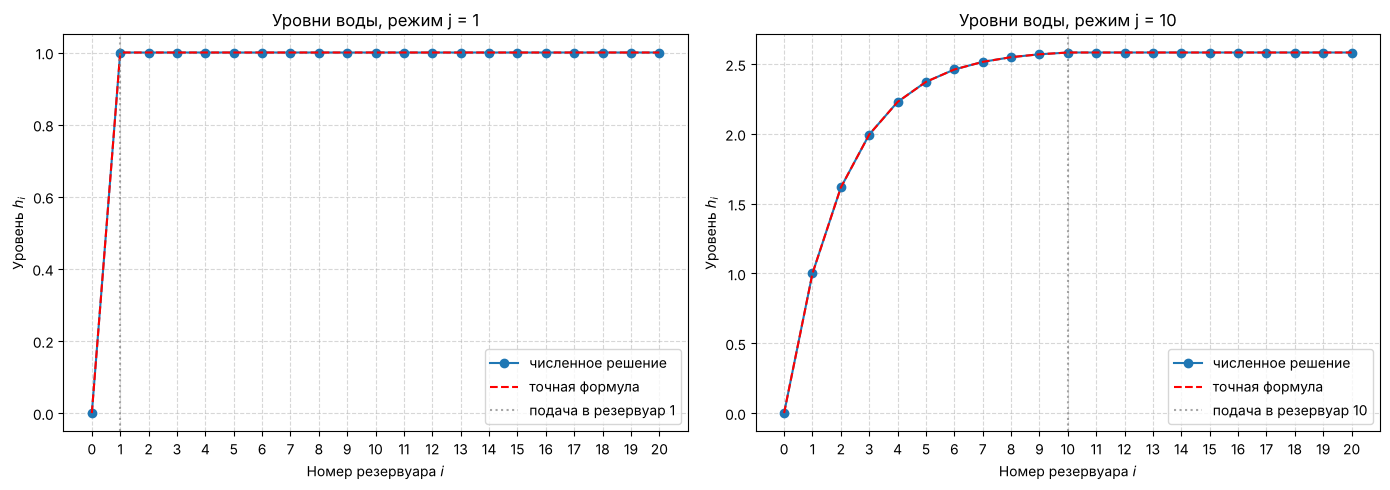

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
reservoirs = np.arange(RESERVOIRS + 1)

for ax, j in zip(axes, [1, 10]):
    h_num = np.concatenate(([0.0], solutions[j]))
    h_exact = np.concatenate(([0.0], exact_levels(j)))
    ax.plot(reservoirs, h_num, marker="o", label="численное решение")
    ax.plot(reservoirs, h_exact, linestyle="--", color="r", label="точная формула")
    ax.axvline(j, color="gray", linestyle=":", alpha=0.7, label=f"подача в резервуар {j}")
    ax.set_title(f"Уровни воды, режим j = {j}")
    ax.set_xlabel("Номер резервуара $i$")
    ax.set_ylabel("Уровень $h_i$")
    ax.set_xticks(reservoirs)
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Разложение построено один раз, а все десять режимов решены только подстановками. Это возможно, потому что от точки подачи зависит лишь правая часть $f^{(j)} = Qe_j$, а матрица $\widehat K$ одна и та же.

Балансы выполнены до $\sim10^{-15}$: на трубах от точки подачи до резервуара 0 поток равен $Q$, правее точки подачи поток равен нулю (с точностью до округления), как и предсказывает формула. На графиках численное решение совпадает с формулой: уровни растут от резервуара 0 до точки подачи, а дальше остаются постоянными, потому что вода туда не течёт. Ступеньки уменьшаются слева направо, так как $g_i$ растут от $10^{-3}$ до $10$ и падение уровня $Q/g_i$ на трубе становится меньше.

Обратная погрешность $\eta_{\text{back},1} \sim 10^{-18}$--$10^{-17}$, то есть решение точное для почти тех же данных и LDLT устойчиво. Относительная ошибка относительно формулы $\approx 4\cdot10^{-12}$ заметно больше, это влияние обусловленности: $\widetilde\kappa_1(\widehat K) \approx 1.5\cdot10^6$ из-за разброса $g_i$ на четыре порядка, и ориентир $\mathfrak u\widetilde\kappa_1 \approx 1.7\cdot10^{-10}$. Фактическая ошибка ниже ориентира, потому что это лишь оценка сверху. Кроме того, сама формула в `float64` считается с округлением (накопленная сумма $Q/g_l$), так что часть расхождения приходится на неё.

3. Новая система

Неизвестные $h_1, \dots, h_{20}, s$. Балансы и условие на уровни в блочном виде:

$$\begin{bmatrix}\widehat K & c\\ c^\top & 0\end{bmatrix}\begin{bmatrix}h\\ s\end{bmatrix} = \begin{bmatrix}f^{(10)}\\ 5\end{bmatrix},\qquad c = e_1 - e_{20}.$$

Матрица симметричная, но уже не положительно определённая: на диагонали стоит 0, и $[0, \dots, 0, 1]\,H\,[0, \dots, 0, 1]^\top = 0$.

Какие разложения применимы при этом порядке неизвестных:

* **LUP** -- да, он существует для любой невырожденной матрицы. Матрица невырождена: $\det H = \det\widehat K\cdot(-c^\top\widehat K^{-1}c)$, а $c^\top\widehat K^{-1}c > 0$, так как $\widehat K^{-1}$ тоже SPD и $c \ne 0$.
* **QR** -- да, отражения Хаусхолдера применимы к любой матрице.
* **LDLT** -- да. Матрица симметричная, ведущие миноры порядка $k \le 20$ совпадают с минорами SPD-матрицы $\widehat K$ и положительны, а полный определитель ненулевой. Значит, все $d_k \ne 0$. При этом $d_{21} = -c^\top\widehat K^{-1}c < 0$. Важно, что порядок неизвестных именно такой: если поставить $s$ первой, то $a_{11} = 0$ и LDLT без выбора ведущего элемента сломается на первом шаге.

Выбираем LDLT: он использует симметрию, а все $d_k \ne 0$ гарантированы. Ответ сверим с LUP.

**Ограниченность факторов для SPD.** Из $A = LDL^\top$ и $l_{ii} = 1$:

$$a_{ii} = \sum_{j<i} l_{ij}^2 d_j + d_i.$$

Для SPD все $d_j > 0$, поэтому каждое слагаемое неотрицательно и не превосходит суммы: $d_i \le a_{ii}$ и $l_{ik}^2 d_k \le a_{ii}$, то есть $|l_{ik}|\sqrt{d_k} \le \sqrt{a_{ii}}$. Факторы ограничены элементами самой матрицы, роста элементов нет.

In [8]:
c = np.zeros(RESERVOIRS)
c[0], c[-1] = 1.0, -1.0
f10 = inflow(10)

H = np.block([[K_hat, c[:, None]],
              [c[None, :], np.zeros((1, 1))]])
rhs = np.concatenate((f10, [LEVEL_DIFFERENCE]))

L_H, d_H = ldlt_factor(H)

# -c^T K_hat^{-1} c через старое разложение K_hat
schur = -c @ ldlt_solve(L, d, c)
print(f"d_21 = {d_H[-1]:.6e},   -c^T K_hat^(-1) c = {schur:.6e}")
print(f"d_1..d_20 > 0: {np.all(d_H[:-1] > 0)},   d_21 < 0: {d_H[-1] < 0}")
print()

print("Оценки для SPD-части (строки 1..20):")
diag = np.diag(H)
print(f"  d_k <= a_kk: {np.all(d_H[:-1] <= diag[:-1])}")
bound = np.abs(L_H[:-1, :-1]) * np.sqrt(d_H[:-1])
print(f"  max_ik |l_ik| sqrt(d_k) / sqrt(a_ii) = "
      f"{np.max(bound / np.sqrt(diag[:-1, None])):.4f}")
print()

print("Последняя строка (уравнение c^T h = 5):")
last = np.abs(L_H[-1, :-1]) * np.sqrt(d_H[:-1])
print(f"  a_21,21 = {diag[-1]:.1f}")
print(f"  max_k |l_21,k| sqrt(d_k) = {last.max():.4e}")
print(f"  max_k |l_21,k|           = {np.abs(L_H[-1]).max():.4e}")

d_21 = -1.602977e+03,   -c^T K_hat^(-1) c = -1.602977e+03
d_1..d_20 > 0: True,   d_21 < 0: True

Оценки для SPD-части (строки 1..20):
  d_k <= a_kk: True
  max_ik |l_ik| sqrt(d_k) / sqrt(a_ii) = 1.0000

Последняя строка (уравнение c^T h = 5):
  a_21,21 = 0.0
  max_k |l_21,k| sqrt(d_k) = 3.1419e+01
  max_k |l_21,k|           = 1.6030e+03


Для первых 20 строк оценки выполняются: все $d_k > 0$, $d_k \le a_{kk}$, а $|l_{ik}|\sqrt{d_k} \le \sqrt{a_{ii}}$ (отношение ровно 1, на границе оценки). Это та же SPD-матрица $\widehat K$, её факторы совпадают с факторами из пункта 2.

Для новой системы гарантии нет. В последней строке $a_{21,21} = 0$, а равенство $0 = \sum_j l_{21,j}^2d_j + d_{21}$ выполняется за счёт отрицательного $d_{21} \approx -1603$. Отрицательное слагаемое может компенсировать сколь угодно большие положительные, поэтому множители ничем не ограничены: здесь $|l_{21,k}|\sqrt{d_k}$ доходит до $31$ при $\sqrt{a_{21,21}} = 0$, а сами $|l_{21,k}|$ до $1603$. Значение $d_{21}$ совпало с $-c^\top\widehat K^{-1}c$, как и должно быть для последнего шага.

4. Проверка результата

In [9]:
solution = ldlt_solve(L_H, d_H, rhs)
h_dev, s = solution[:-1], solution[-1]

L_P, U_P, p_P = lup_factor(H)
solution_lup = lup_solve(L_P, U_P, p_P, rhs)

print(f"s = {s:.6e}")
print(f"||K_hat h + c s - f||_inf = {np.linalg.norm(K_hat @ h_dev + c * s - f10, np.inf):.3e}")
print(f"h_1 - h_20 - 5           = {h_dev[0] - h_dev[-1] - LEVEL_DIFFERENCE:.3e}")
print(f"eta_back,1 (вся система) = {backward_error_1(H, solution, rhs):.3e}")
print(f"отличие от LUP           = {relative_error(solution_lup, solution):.3e}")

s = -4.106552e-03
||K_hat h + c s - f||_inf = 7.105e-15
h_1 - h_20 - 5           = -8.882e-16
eta_back,1 (вся система) = 4.353e-18
отличие от LUP           = 2.277e-12


In [10]:
h_before = solutions[10]
phi_before, phi_after = flows(h_before), flows(h_dev)

print(f"{'i':>3} {'h до':>11} {'h после':>11} {'phi до':>11} {'phi после':>11}")
for i in range(1, RESERVOIRS + 1):
    print(f"{i:>3} {h_before[i - 1]:>11.4f} {h_dev[i - 1]:>11.4f} "
          f"{phi_before[i - 1]:>11.3e} {phi_after[i - 1]:>11.3e}")

  i        h до     h после      phi до   phi после
  1      1.0000      1.0000   1.000e-03   1.000e-03
  2      1.6158     -0.9132   1.000e-03  -3.107e-03
  3      1.9951     -2.0914   1.000e-03  -3.107e-03
  4      2.2287     -2.8170   1.000e-03  -3.107e-03
  5      2.3725     -3.2638   1.000e-03  -3.107e-03
  6      2.4611     -3.5390   1.000e-03  -3.107e-03
  7      2.5157     -3.7085   1.000e-03  -3.107e-03
  8      2.5493     -3.8129   1.000e-03  -3.107e-03
  9      2.5700     -3.8772   1.000e-03  -3.107e-03
 10      2.5827     -3.9168   1.000e-03  -3.107e-03
 11      2.5827     -3.9490   3.961e-15  -4.107e-03
 12      2.5827     -3.9688   3.951e-15  -4.107e-03
 13      2.5827     -3.9811   4.178e-15  -4.107e-03
 14      2.5827     -3.9886   4.119e-15  -4.107e-03
 15      2.5827     -3.9932   3.934e-15  -4.107e-03
 16      2.5827     -3.9961   4.472e-15  -4.107e-03
 17      2.5827     -3.9978   4.149e-15  -4.107e-03
 18      2.5827     -3.9989   3.369e-15  -4.107e-03
 19      2.5

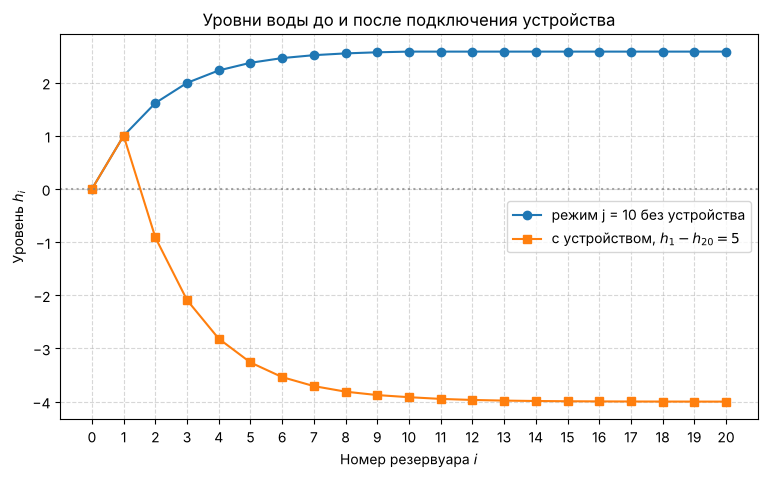

In [11]:
plt.figure(figsize=(9, 5))
plt.plot(reservoirs, np.concatenate(([0.0], h_before)), marker="o", label="режим j = 10 без устройства")
plt.plot(reservoirs, np.concatenate(([0.0], h_dev)), marker="s", label="с устройством, $h_1 - h_{20} = 5$")
plt.axhline(0, color="gray", linestyle=":", alpha=0.7)
plt.title("Уровни воды до и после подключения устройства")
plt.xlabel("Номер резервуара $i$")
plt.ylabel("Уровень $h_i$")
plt.xticks(reservoirs)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Можно ли использовать прежнее разложение $\widehat K$. Исключим $h$ из блочной системы: $h = \widehat K^{-1}(f - cs)$, подставим в $c^\top h = 5$:

$$s = \frac{c^\top y - 5}{c^\top w},\qquad h = y - s\,w,\qquad \widehat Ky = f,\ \ \widehat Kw = c.$$

Это два решения с уже готовыми факторами $\widehat K$, то есть новое разложение не нужно.

In [12]:
y = ldlt_solve(L, d, f10)
w = ldlt_solve(L, d, c)
s_reuse = (c @ y - LEVEL_DIFFERENCE) / (c @ w)
h_reuse = y - s_reuse * w

print(f"s через старое разложение = {s_reuse:.6e}")
print(f"отличие h от решения LDLT(H) = {relative_error(h_reuse, h_dev):.3e}")

s через старое разложение = -4.106552e-03
отличие h от решения LDLT(H) = 3.425e-16


Невязка балансов $\sim10^{-15}$, условие $h_1 - h_{20} = 5$ выполнено до $\sim10^{-16}$, обратная погрешность всей системы $\sim10^{-18}$. Несмотря на большие множители в последней строке, на этой задаче LDLT дал устойчивый результат, а с LUP ответ совпал до $\sim10^{-12}$, то есть в пределах влияния обусловленности.

$s \approx -4.1\cdot10^{-3} < 0$, значит, вода идёт против выбранного положительного направления: устройство забирает воду из резервуара 20 и подаёт в резервуар 1. Без устройства $h_1 - h_{20} = 1 - 2.58 = -1.58$, а нужно $+5$, поэтому уровень в резервуаре 1 надо поднять относительно 20.

Возникла циркуляция: из резервуара 1 поток $Q$ уходит в резервуар 0 (поэтому $h_1 = 1$ не изменился), а $3.1\cdot10^{-3}$ идёт по трубам $2, \dots, 10$ к точке подачи. В резервуаре 10 к нему добавляется подача $Q$, и $4.1\cdot10^{-3}$ течёт по трубам $11, \dots, 20$ к резервуару 20, откуда устройство возвращает воду в резервуар 1. Уровни в резервуарах $2, \dots, 20$ стали отрицательными, ниже резервуара 0, и убывают до $h_{20} = -4$.

При переносе точки подачи меняется только правая часть $f^{(j)}$, матрица $\widehat K$ та же, поэтому прежнее разложение используется без изменений (так решены все режимы в пункте 2). При добавлении устройства меняется сама матрица: добавляются строка и столбец $c$, и разложение $\widehat K$ напрямую не подходит. Но через исключение $h$ (дополнение Шура) достаточно двух решений с прежними факторами $\widehat K$, и результат совпал с решением через LDLT новой матрицы до $\sim10^{-16}$.